**Tutorial Code by Amirhossein Ahrari YouTube:** https://www.youtube.com/@amirhosseinahrarigee

**Tutorial Video: PySTAC Tutorial-17: Sentinel-2 LandCover Threshold Analysis using NDVI and KMeans in Python**

This code is part of a tutorial series on python eo programming techniques
presented on the Amirhossein Ahrari YouTube channel. You are free to use and modify
this code for academic and non-academic purposes. Don't forget to subscribe to
the Amirhossein Ahrari channel and follow the videos to support the instructor.

In [1]:
!pip install -q pystac_client

In [2]:
from pystac_client import Client

In [3]:
catalog = Client.open(
    'https://earth-search.aws.element84.com/v1'
)

In [4]:
for collection in catalog.get_collections():
  print(collection.id)

sentinel-2-pre-c1-l2a
cop-dem-glo-30
naip
cop-dem-glo-90
landsat-c2-l2
sentinel-2-l2a
sentinel-2-l1c
sentinel-2-c1-l2a
sentinel-1-grd


In [5]:
bbox = [51.048091, 36.706832, 51.095111, 36.744824]

In [6]:
search = catalog.search(
    collections = ['sentinel-2-c1-l2a'],
    datetime = '2025',
    bbox = bbox
)

In [7]:
items = search.item_collection()

In [8]:
len(items)

174

In [10]:
items[0].properties['proj:code']

'EPSG:32639'

In [12]:
items[0].assets.keys()

dict_keys(['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail'])

In [13]:
!pip install -q stackstac
from stackstac import stack

In [14]:
items_stack = stack(
    items,
    assets = ['red','nir', 'scl'],
    epsg = 32639,
    resolution = 10,
    bounds_latlon = bbox
)

In [20]:
ds = (
    items_stack.to_dataset('band')
    .drop_dims('band')
    .reset_coords(drop = True)
    .drop_attrs()

)

In [21]:
mask = ds.scl.isin([0,1,3,8,9,10,11]).astype(int)
ds_mask = ds[['nir','red']].where(mask == 0)

In [22]:
red = ds_mask['red']
nir = ds_mask['nir']
ndvi = (nir - red) / (nir + red)

In [23]:
ndvi_monthly = ndvi.resample(time = 'MS').max('time')

In [24]:
ndvi_monthly

<xarray.DataArray (time: 12, y: 422, x: 421)> Size: 17MB
dask.array<stack, shape=(12, 422, 421), dtype=float64, chunksize=(1, 422, 421), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 96B 2025-01-01 2025-02-01 ... 2025-12-01
  * y        (y) float64 3kB 4.067e+06 4.067e+06 ... 4.062e+06 4.062e+06
  * x        (x) float64 3kB 5.043e+05 5.043e+05 ... 5.085e+05 5.085e+05

In [25]:
from dask.diagnostics import ProgressBar

In [27]:
import warnings
warnings.filterwarnings('ignore', category = RuntimeWarning)
import logging
logging.getLogger().setLevel(logging.ERROR)

In [28]:
with ProgressBar():
  ndvi_monthly = ndvi_monthly.compute()

[########################################] | 100% Completed | 117.41 s


In [30]:
ndvi_mean = ndvi_monthly.median('time')

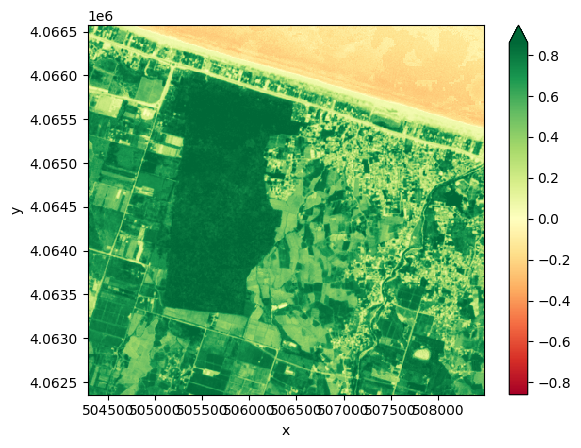

In [31]:
ndvi_mean.plot(
    robust = True,
    cmap = 'RdYlGn'
)

In [32]:
from sklearn.cluster import KMeans

In [33]:
import numpy as np

In [34]:
ndvi_val = ndvi_mean.values
ndvi_mask = np.isfinite(ndvi_val)

In [40]:
ndvi_val.shape

(422, 421)

In [41]:
ndvi_val.reshape(-1,1).shape

(177662, 1)

In [42]:
model = KMeans(n_clusters = 4, random_state = 42)
label = model.fit_predict(ndvi_val[ndvi_mask].reshape(-1,1))

In [45]:
import xarray as xr

In [50]:
xr_label = xr.full_like(
    ndvi_mean, np.nan
)

xr_label.values[ndvi_mask] = label

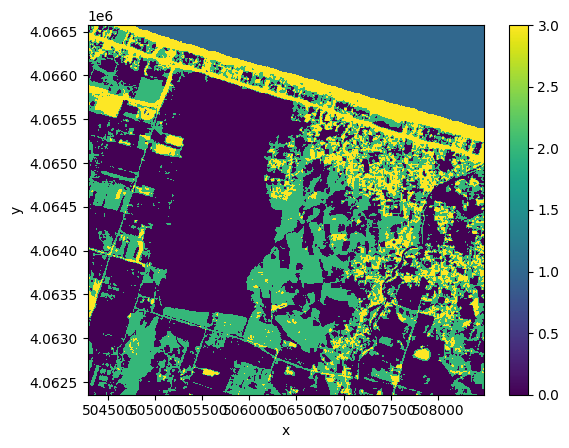

In [52]:
xr_label.plot()

In [61]:
for i in np.unique(xr_label.values):
  cls_mean = ndvi_mean.where(xr_label == i).mean(dim = ['y','x']).item()
  cls_max = ndvi_mean.where(xr_label == i).max(dim = ['y','x']).item()
  cls_min = ndvi_mean.where(xr_label == i).min(dim = ['x','y']).item()
  print(f'class {i} mean: {cls_mean:.2f}')
  print(f'class {i} max: {cls_max:.2f}')
  print(f'class {i} min: {cls_min:.2f}')
  print('-----------------------------')

class 0.0 mean: 0.78
class 0.0 max: 0.90
class 0.0 min: 0.65
-----------------------------
class 1.0 mean: -0.17
class 1.0 max: 0.04
class 1.0 min: -0.28
-----------------------------
class 2.0 mean: 0.52
class 2.0 max: 0.65
class 2.0 min: 0.38
-----------------------------
class 3.0 mean: 0.24
class 3.0 max: 0.38
class 3.0 min: 0.04
-----------------------------


In [67]:
thr = [0.04, 0.38, 0.65]

ndvi_map = np.digitize(ndvi_val, bins = thr)
ndvi_map = xr.DataArray(
    ndvi_map,
    dims = ndvi_mean.dims,
    coords = ndvi_mean.coords
) + 1

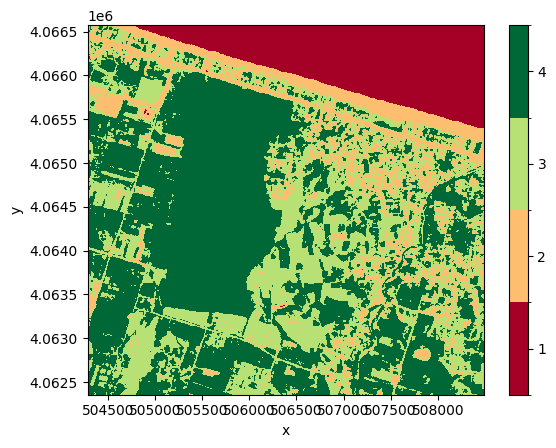

In [71]:
ndvi_map.plot(
    cmap = 'RdYlGn', levels = np.arange(0.5, 5, 1),
    cbar_kwargs = {'ticks': range(5)}
)